# MISY331: NFT Price Prediction

**Research question:** can NFT traits predict a later group of sale amounts, and do small neural networks improve on basic machine learning?

This report extends MISY331 Assignment 5 with chronological evaluation, train-only preprocessing, and an explicit PyTorch MLP training loop. It uses Harry Wang's [Crypto Coven dataset](https://huggingface.co/datasets/harrywang/crypto-coven), collected on 21 April 2022. It reports a historical sale snapshot rather than a trading backtest.

**Execution:** this notebook reads the saved CLI experiment by default. Set `RUN_TRAINING = True` to refit all models before inspecting results. Training lives in `src/`, so there is one implementation to maintain.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'train.py').exists(), 'Run from the project root or notebooks folder.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import FEATURES, load_data, chronological_split
from src.train import metrics, run_experiment
RUN_TRAINING = False
if RUN_TRAINING:
    run_experiment(ROOT / 'data' / 'witches_traits.csv', ROOT / 'results')
print('Source: included curated traits. Results: ' + ('fresh fit' if RUN_TRAINING else 'saved CLI experiment'))

Source: included curated traits. Results: saved CLI experiment


## 1. Data and target

The distributed file retains all 9,764 source rows but only 32 traits, token ID, sale amount, and sale timestamp. The expanded original export was checked: payment tokens are ETH/WETH with 18 decimals. Convert the raw amount from wei using `10**18`; avoid snapshot-dependent USD conversions.

Drop missing/nonpositive prices and invalid timestamps, then keep one latest record per token. Owner identity, cumulative sales counts, and token metadata are excluded from predictors. Token ID and time are used only for deduplication and splitting.

In [2]:
frame, audit = load_data(ROOT / 'data' / 'witches_traits.csv')
parts = chronological_split(frame)
keys = ['raw_rows', 'missing_sale_price_rows', 'invalid_or_nonpositive_price_rows',
        'duplicate_priced_tokens_removed', 'eligible_unique_tokens']
display(pd.Series({k: audit[k] for k in keys}, name='records').to_frame())
print(f'{len(FEATURES)} predictors; target: {audit["target"]}')
assert len(frame) == 4895
assert frame.token_id.is_unique
assert 'owner.address' not in FEATURES and 'num_sales' not in FEATURES

,records
raw_rows,9764
missing_sale_price_rows,4868
invalid_or_nonpositive_price_rows,0
duplicate_priced_tokens_removed,1
eligible_unique_tokens,4895


32 predictors; target: last_sale.total_price / 1e18 (ETH-equivalent units)


## 2. Chronological partitions

Approximate 60/20/20 by sorted record count while keeping UTC calendar days intact. Hyperparameters use the middle window; the last window is reserved for reporting. These irregular observations have unequal calendar durations.

A latest-sale snapshot selects sold tokens and overwrites prior transactions. Chronological separation avoids mixing later sales into training, but it does not remove snapshot selection bias or prove a live investment setting.

,rows,start_utc,end_utc,mean_eth,median_eth,p90_eth
window,,,,,,
train,2901,2021-11-07,2022-01-22,0.5824,0.279,1.500
validation,998,2022-01-23,2022-02-09,2.7401,2.500,3.500
test,996,2022-02-10,2022-04-21,1.4005,1.200,2.165


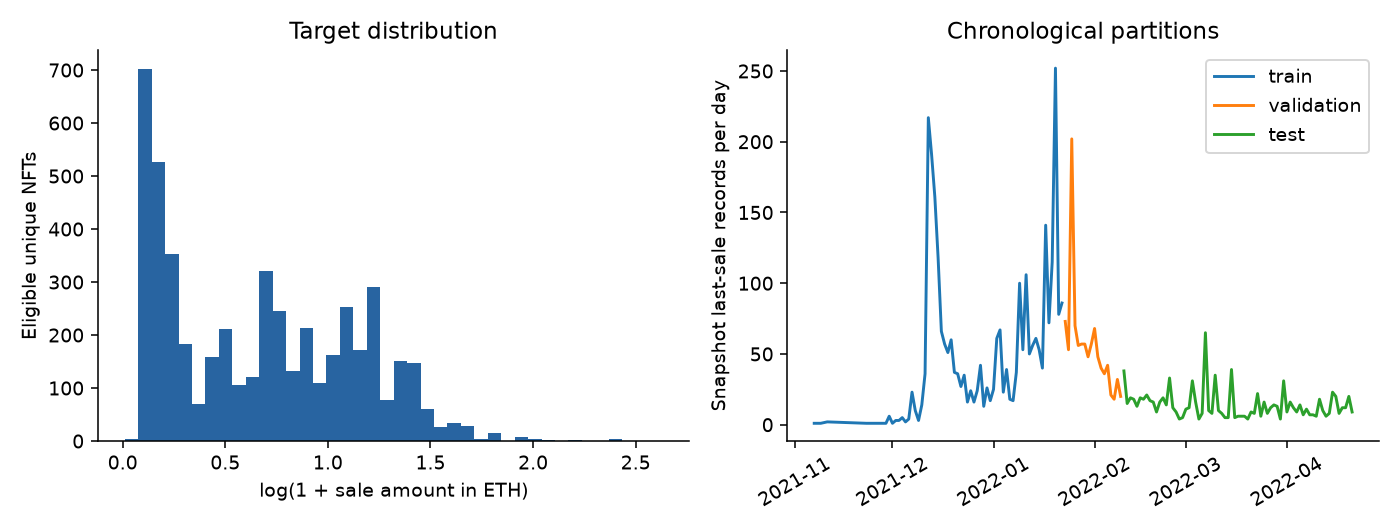

In [3]:
partition_summary = []
for name, part in parts.items():
    partition_summary.append({'window': name, 'rows': len(part),
        'start_utc': part.sale_time.min().strftime('%Y-%m-%d'),
        'end_utc': part.sale_time.max().strftime('%Y-%m-%d'),
        'mean_eth': part.price_eth.mean(), 'median_eth': part.price_eth.median(),
        'p90_eth': part.price_eth.quantile(.9)})
display(pd.DataFrame(partition_summary).set_index('window').round(4))
assert parts['train'].sale_time.max() < parts['validation'].sale_time.min()
assert parts['validation'].sale_time.max() < parts['test'].sale_time.min()
display(Image(filename=str(ROOT / 'results' / 'data_and_split.png')))

## 3. Methods

- **Baselines:** raw-price mean and median from the fitting window.
- **Linear:** ordinary least squares, Ridge, and SGD regression.
- **Trees:** random forest and histogram gradient boosting.
- **Neural:** ReLU MLPs with one or two hidden layers, Adam, L2 weight decay and optional dropout.

Numeric median imputation, standardization, categorical absence labels, rare-category pooling and one-hot encoding are fitted on the training slice only. Future unseen categories are ignored. The interpretation of missing traits is imperfect: some represent absent accessories; others may be unknown.

All learned estimators minimize squared error on `log1p(ETH)`. Neural targets are also standardized with training-only statistics. Predictions invert `expm1` and floor at zero. A log-space inverse is not an unbiased raw-price conditional mean.

Candidates are chosen by validation RMSLE using seed 42. MLPs choose the epoch by validation log MSE, then compare candidates by clipped RMSLE. Finally, refit on train + validation with the chosen epoch fixed. Test data do not determine imputation, tuning, or early stopping. Small search grids have different budgets across methods; this is a basic comparison rather than exhaustive tuning.

In [4]:
experiment = json.loads((ROOT / 'results' / 'experiment.json').read_text())
selection = pd.DataFrame.from_dict(experiment['selected_models'], orient='index')
display(selection[['parameters', 'epochs', 'validation_rmsle']])
print('Recorded Python:', experiment['python'])
print('Recorded packages:', experiment['versions'])
print('Selection seed:', experiment['selection_seed'], '; final seeds:', experiment['seeds'])
# Include constant baselines in the earlier validation comparison.
validation_baselines = []
for strategy in ['mean', 'median']:
    constant = getattr(parts['train'].price_eth, strategy)()
    score = metrics(parts['validation'].price_eth, np.full(len(parts['validation']), constant))
    validation_baselines.append({'model': strategy.title() + ' baseline', **score})
display(pd.DataFrame(validation_baselines).round(4))

,parameters,epochs,validation_rmsle
Linear regression,{},NaN,0.933902
Ridge,{'alpha': 100.0},NaN,0.923394
SGD regression,{'alpha': 0.001},NaN,0.927247
Random forest,"{'max_depth': 8, 'min_samples_leaf': 2}",NaN,0.922954
Gradient boosting,"{'max_leaf_nodes': 7, 'l2_regularization': 1.0}",NaN,0.925093
Shallow MLP,"{'hidden': [64], 'dropout': 0.1}",13.0,0.909188
Deep MLP,"{'hidden': [64, 32], 'dropout': 0.0}",8.0,0.892131


Recorded Python: 3.12.14
Recorded packages: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'torch': '2.14.1+cpu', 'matplotlib': '3.11.2'}
Selection seed: 42 ; final seeds: [42, 7, 2026]


,model,rmse_eth,mae_eth,rmsle,r2
0,Mean baseline,2.3388,2.1589,0.8615,-5.7179
1,Median baseline,2.6213,2.4616,1.0698,-7.4387


## 4. Later-sale test results

RMSLE is the primary comparison metric; ETH RMSE and MAE show error in sale-amount units. R2 is also reported. Stochastic models use seeds 42, 7, 2026; OLS, Ridge and constant baselines run once. The bar whiskers represent seed standard deviation, **not confidence intervals**. Histogram boosting is identical across these seeds in this configuration.

,runs,rmsle_mean,rmsle_seed_sd,rmse_eth_mean,mae_eth_mean,r2_mean
model,,,,,,
Mean baseline,1,0.2590,0.0000,0.7651,0.4520,-0.1373
Random forest,3,0.3293,0.0006,0.8948,0.5891,-0.5558
Gradient boosting,3,0.3311,0.0000,0.8955,0.5854,-0.5580
Ridge,1,0.3368,0.0000,0.9004,0.5969,-0.5752
SGD regression,3,0.3537,0.0106,0.9185,0.6242,-0.6399
Linear regression,1,0.3688,0.0000,0.9345,0.6480,-0.6969
Shallow MLP,3,0.3781,0.0048,0.9461,0.6640,-0.7392
Deep MLP,3,0.4140,0.0040,0.9992,0.7191,-0.9398
Median baseline,1,0.4725,0.0000,1.1126,0.8527,-1.4053


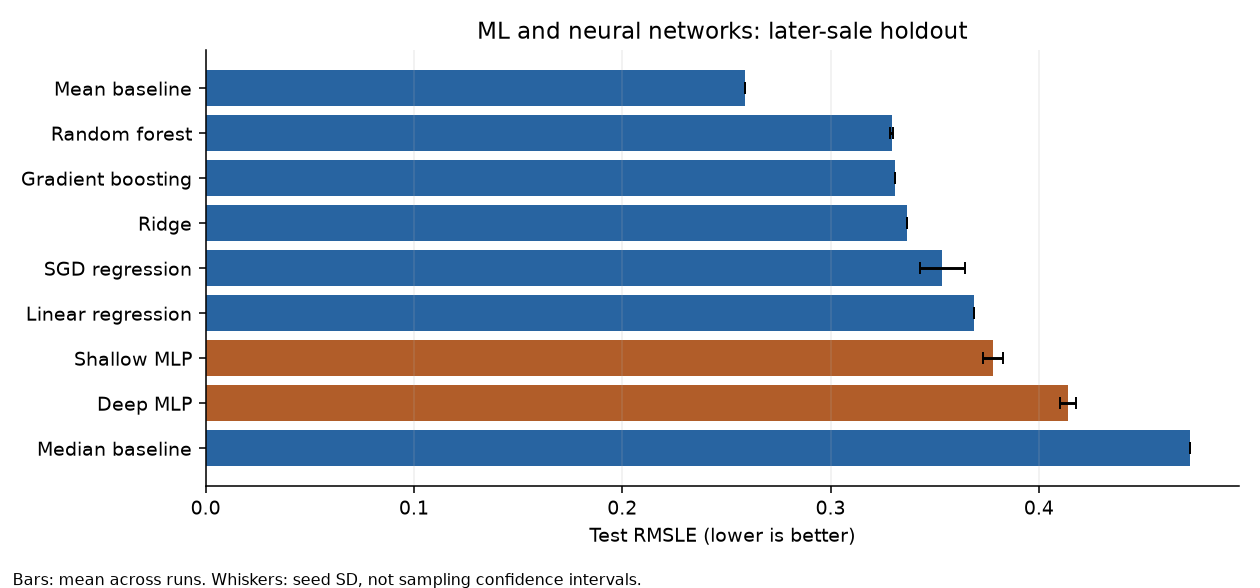

Mean baseline RMSLE: 0.2590
Every learned model exceeds the mean baseline: True


In [5]:
comparison = pd.read_csv(ROOT / 'results' / 'comparison.csv')
display(comparison.set_index('model').round(4))
display(Image(filename=str(ROOT / 'results' / 'model_comparison.png')))
mean_score = comparison.set_index('model').loc['Mean baseline', 'rmsle_mean']
learned = comparison[~comparison.model.str.contains('baseline')]
print(f'Mean baseline RMSLE: {mean_score:.4f}')
print('Every learned model exceeds the mean baseline:', bool((learned.rmsle_mean > mean_score).all()))

## 5. Learning curves and prediction diagnostics

Both MLPs reduce training error while validation error remains much higher and does not improve consistently. That gap is compatible with poor generalization. A single time split cannot separate memorization from temporal distribution shift or quantify financial signal-to-noise.

The plotted prediction diagnostics use seed 42; summary scores average the recorded seeds. Static traits miss much of the high-price variation.

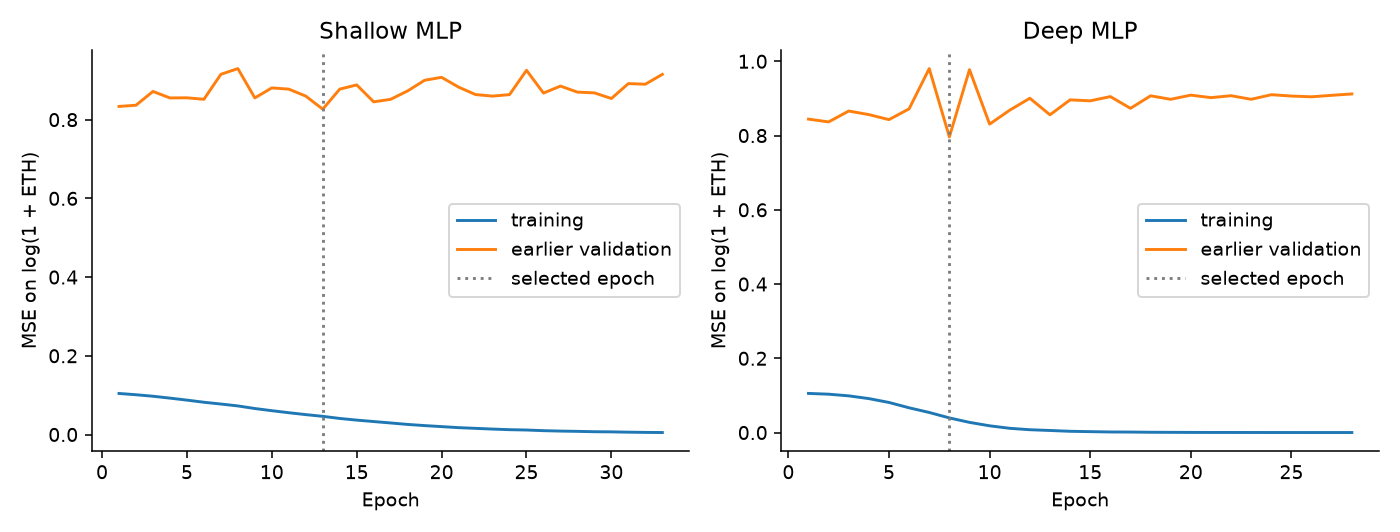

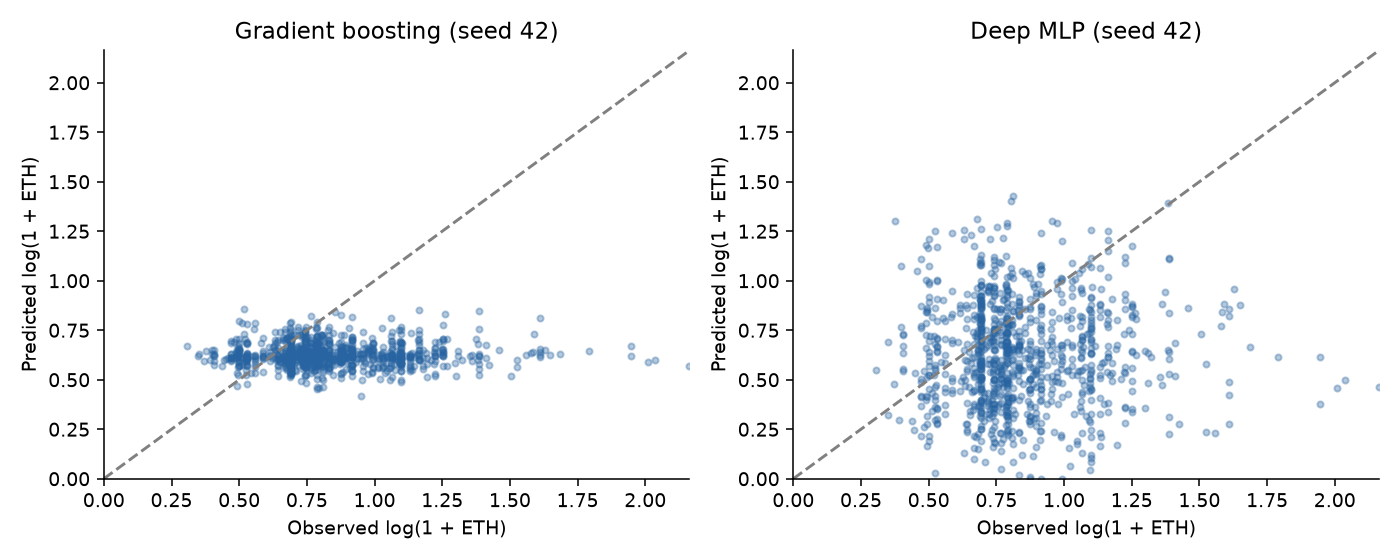

In [6]:
display(Image(filename=str(ROOT / 'results' / 'mlp_learning_curves.png')))
display(Image(filename=str(ROOT / 'results' / 'prediction_diagnostics.png')))

## 6. What this experiment supports

The mean baseline has test RMSLE **0.2590**, random forest **0.3293**, shallow MLP **0.3781**, and deep MLP **0.4140**. No learned model beats the mean baseline. All learned models have negative test R2. R2's reference uses the observed test mean, unlike the deployable mean baseline estimated from earlier data.

The price distribution changes markedly across windows: median ETH is **0.279 / 2.500 / 1.200** for training / validation / test. The best learned validation candidate is the deep MLP, but it generalizes worse than the shallow MLP on the later test window. Even on validation, the training-only mean baseline (RMSLE **0.8615**) beats that deep MLP (**0.8921**).

This supports caution about architecture complexity and static-trait price prediction in a changing market. It does not establish universal tree superiority, causal trait effects, profitable return signals, or a numerical estimate of signal-to-noise. The result is specific to one NFT collection, one snapshot, one split and a limited search.

后续真正值得研究的是：在多个时间窗口中是否还能稳定超过基准，以及获得完整交易历史后，哪些时点可知的信息有助于解释价格变化。当前项目保留基础方法比较和真实负面结果，不把它包装成投资策略。

## Reproduction and verification

Run `python -m src.train` from the root to regenerate metrics and figures. Run `python -m pytest -q --basetemp .test-tmp-local` for five focused tests covering price units, deduplication, chronological separation, train-only transformations, metrics and seeded neural fitting. Source attribution and unit checks are in `data/README.md`; package pins are in `requirements.txt`.